In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [110]:
titanic=pd.read_csv("/content/Titanic-Dataset.csv")

In [111]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


/tmp/ipykernel_1722/299476904.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived',data=titanic,palette='RdBu_r')


<Axes: xlabel='Survived', ylabel='count'>

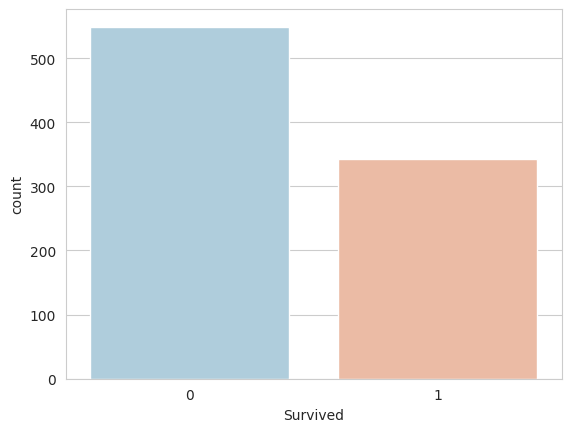

In [112]:
sns.set_style('whitegrid')
sns.countplot(x='Survived',data=titanic,palette='RdBu_r')

<Axes: xlabel='Survived', ylabel='count'>

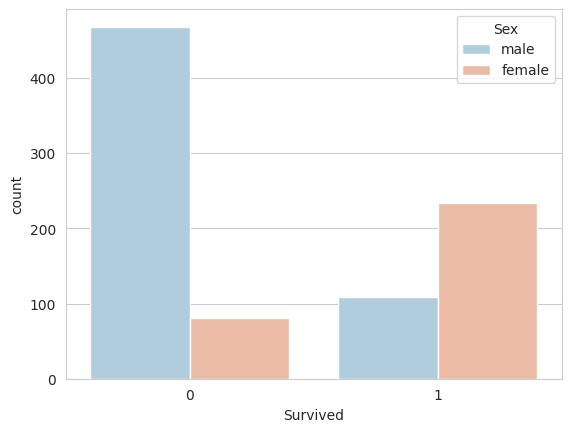

In [113]:
sns.countplot(x='Survived',hue='Sex',data=titanic,palette='RdBu_r')

<Axes: xlabel='Survived', ylabel='count'>

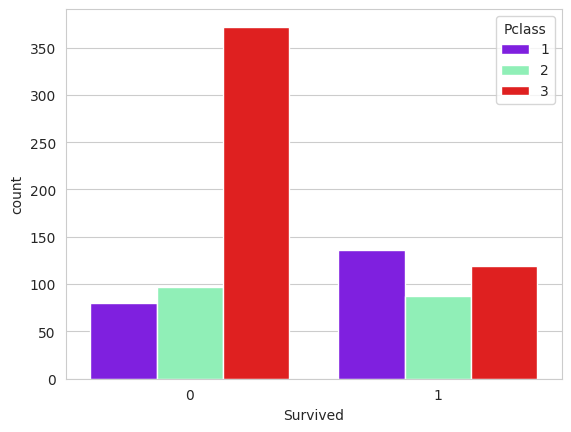

In [114]:
sns.countplot(x='Survived',hue='Pclass',data=titanic,palette='rainbow')

/tmp/ipykernel_1722/3716348026.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic["Age"],kde=False,color='darkred' ,bins=30)


<Axes: xlabel='Age'>

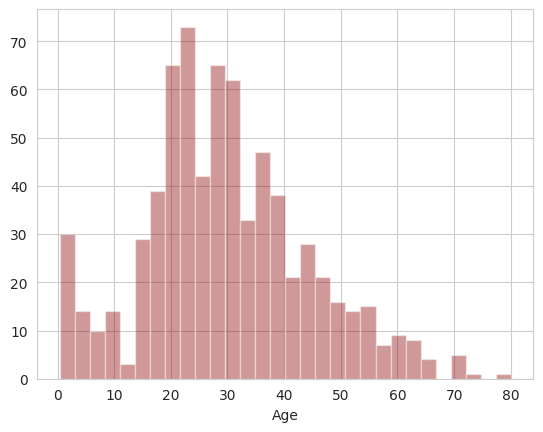

In [115]:
sns.distplot(titanic["Age"],kde=False,color='darkred' ,bins=30)

In [116]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


<Axes: >

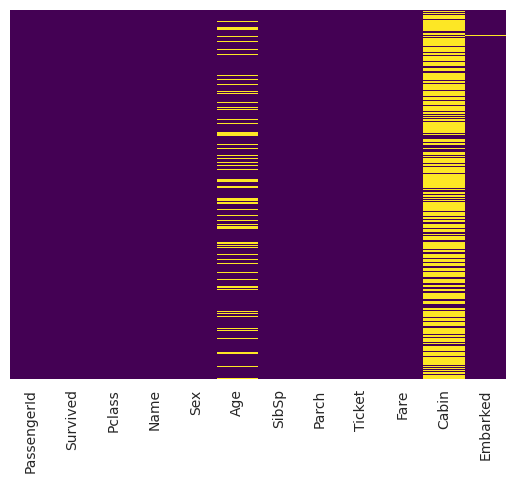

In [117]:
sns.heatmap(titanic.isnull(),yticklabels=False,cbar=False,cmap='viridis')

/tmp/ipykernel_1722/3050390973.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass',y="Age",data=titanic,palette='winter')


<Axes: xlabel='Pclass', ylabel='Age'>

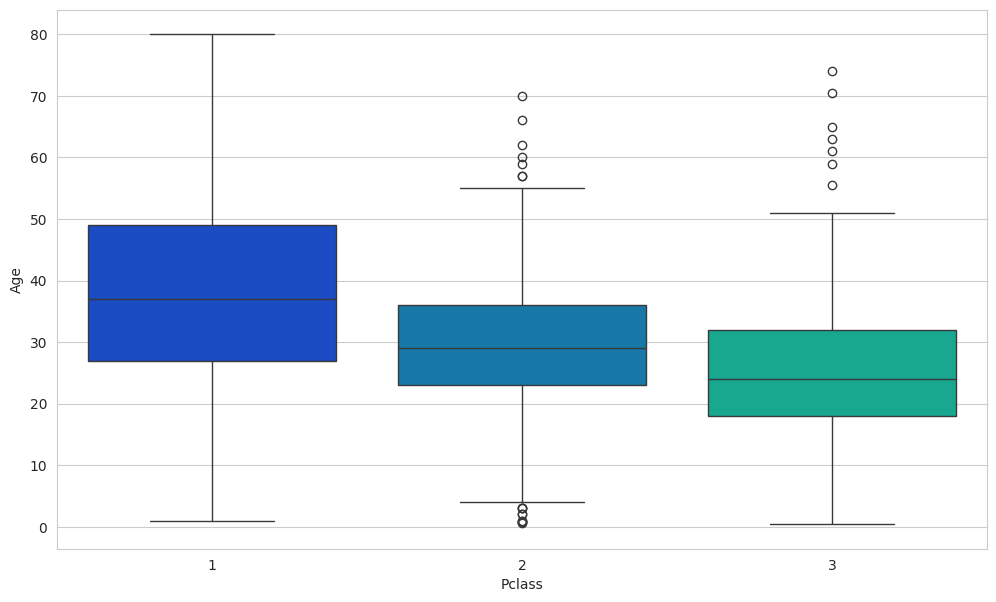

In [118]:
plt.figure(figsize=(12,7))
sns.boxplot(x='Pclass',y="Age",data=titanic,palette='winter')

In [119]:
def impute_age(cols):
  Age=cols[0]
  Pclass=cols[1]
  if pd.isnull(Age):
    if Pclass==1:
      return 37
    elif Pclass==2:
      return 29
    else:
        return 24
  else:
     return Age

In [120]:
titanic['Age']=titanic[['Age','Pclass']].apply(impute_age,axis=1)

/tmp/ipykernel_1722/1495782096.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age=cols[0]
/tmp/ipykernel_1722/1495782096.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass=cols[1]


<Axes: >

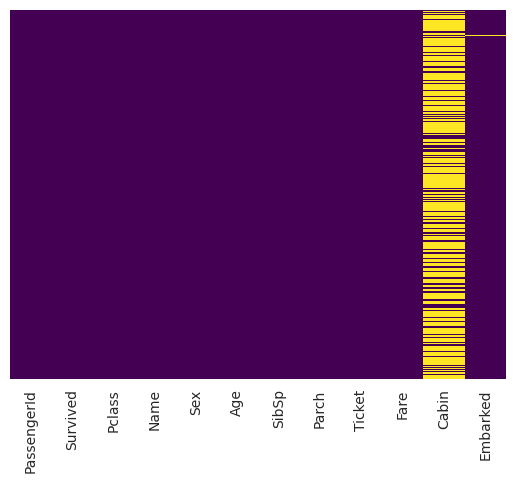

In [121]:
sns.heatmap(titanic.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [122]:
titanic.drop(['Cabin'],inplace=True,axis=1)

In [123]:
titanic.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C


In [124]:
titanic.dropna(inplace=True)

<Axes: >

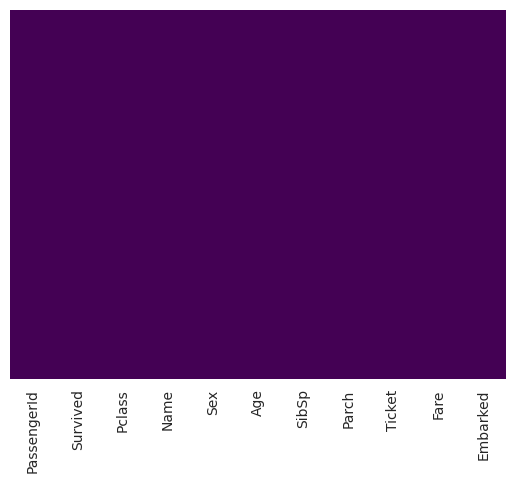

In [125]:
sns.heatmap(titanic.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [126]:
sex=pd.get_dummies(titanic['Sex'], dtype=int,drop_first=True)

In [127]:
embark=pd.get_dummies(titanic['Embarked'], dtype=int,drop_first=True)

In [128]:
titanic.drop(['Sex','Embarked','Name','Ticket'],axis=1,inplace=True)

In [129]:
titanic.head(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1,0,3,22.0,1,0,7.2500
1,2,1,1,38.0,1,0,71.2833


In [130]:
titanic=pd.concat([titanic,sex,embark],axis=1)

In [131]:
titanic.head(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,1,0,3,22.0,1,0,7.2500,1,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0


In [132]:
from sklearn.model_selection import train_test_split

In [133]:
X_train,X_test,Y_train,Y_test=train_test_split(titanic.drop('Survived',axis=1),titanic['Survived'],test_size=0.3,random_state=101)

In [134]:
print(X_train)

     PassengerId  Pclass   Age  SibSp  Parch     Fare  male  Q  S
807          808       3  18.0      0      0   7.7750     0  0  1
651          652       2  18.0      0      1  23.0000     0  0  1
2              3       3  26.0      0      0   7.9250     0  0  1
690          691       1  31.0      1      0  57.0000     1  0  1
196          197       3  24.0      0      0   7.7500     1  1  0
..           ...     ...   ...    ...    ...      ...   ... .. ..
576          577       2  34.0      0      0  13.0000     0  0  1
840          841       3  20.0      0      0   7.9250     1  0  1
338          339       3  45.0      0      0   8.0500     1  0  1
524          525       3  24.0      0      0   7.2292     1  0  0
865          866       2  42.0      0      0  13.0000     0  0  1

[622 rows x 9 columns]


In [135]:
from sklearn.linear_model import LogisticRegression

In [136]:
logmodel=LogisticRegression(solver='liblinear')

In [137]:
logmodel.fit(X_train,Y_train)

LogisticRegression(solver='liblinear')

In [138]:
predictions=logmodel.predict(X_test)

In [139]:
from sklearn.metrics import classification_report
print((classification_report(Y_test,predictions)))

              precision    recall  f1-score   support

           0       0.81      0.93      0.86       163
           1       0.85      0.65      0.74       104

    accuracy                           0.82       267
   macro avg       0.83      0.79      0.80       267
weighted avg       0.82      0.82      0.81       267



In [142]:
from sklearn.metrics import confusion_matrix
print("confusion matrix",confusion_matrix(Y_test,predictions))
tn, fp, fn, tp = confusion_matrix(Y_test, predictions).ravel()
print(tn,fp,fn,tp)

confusion matrix [[151  12]
 [ 36  68]]
151 12 36 68


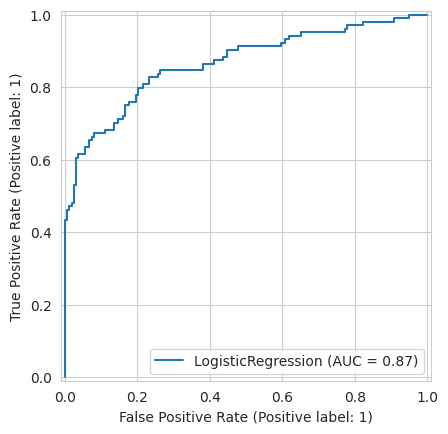

In [146]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(logmodel, X_test, Y_test)
plt.show()